In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [11]:
data = fetch_california_housing(as_frame=True)

df = data.frame

print(df.head())

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [12]:
df = df[['MedInc', 'HouseAge', 'MedHouseVal']]

print(df.head())

   MedInc  HouseAge  MedHouseVal
0  8.3252      41.0        4.526
1  8.3014      21.0        3.585
2  7.2574      52.0        3.521
3  5.6431      52.0        3.413
4  3.8462      52.0        3.422


In [13]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Shape: (20640, 3)

Missing Values:
MedInc         0
HouseAge       0
MedHouseVal    0
dtype: int64

Statistical Summary:
             MedInc      HouseAge   MedHouseVal
count  20640.000000  20640.000000  20640.000000
mean       3.870671     28.639486      2.068558
std        1.899822     12.585558      1.153956
min        0.499900      1.000000      0.149990
25%        2.563400     18.000000      1.196000
50%        3.534800     29.000000      1.797000
75%        4.743250     37.000000      2.647250
max       15.000100     52.000000      5.000010


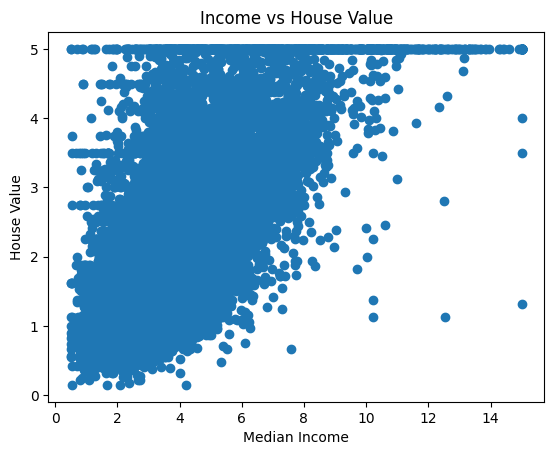

In [14]:
plt.scatter(df['MedInc'], df['MedHouseVal'])

plt.xlabel('Median Income')
plt.ylabel('House Value')

plt.title('Income vs House Value')

plt.show()

               MedInc  HouseAge  MedHouseVal
MedInc       1.000000 -0.119034     0.688075
HouseAge    -0.119034  1.000000     0.105623
MedHouseVal  0.688075  0.105623     1.000000


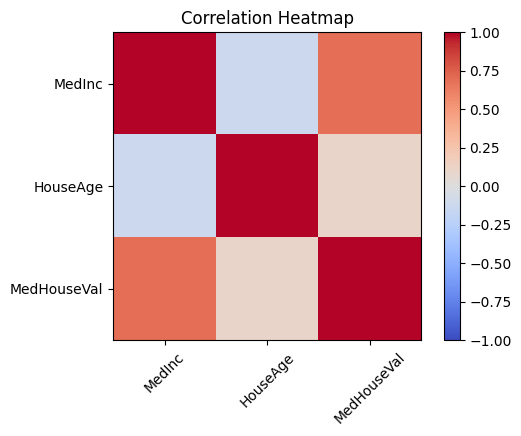

In [15]:
print(df.corr())

plt.figure(figsize=(6, 4))

plt.imshow(df.corr(), cmap='coolwarm', vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(range(3), df.columns, rotation=45)
plt.yticks(range(3), df.columns)

plt.title("Correlation Heatmap")

plt.show()

In [16]:
sample = df.head(6)

X_manual = np.column_stack((
    np.ones(6),
    sample['MedInc'],
    sample['HouseAge']
))

y_manual = sample['MedHouseVal'].values

# Normal equation
XTX = X_manual.T @ X_manual
XTY = X_manual.T @ y_manual

# Calculate coefficients
b = np.linalg.solve(XTX, XTY)

print("XTX:\n", XTX)
print("\nXTY:\n", XTY)

print("\nIntercept:", b[0])
print("MedInc Coefficient:", b[1])
print("HouseAge Coefficient:", b[2])

XTX:
 [[6.00000000e+00 3.74101000e+01 2.70000000e+02]
 [3.74101000e+01 2.53825638e+02 1.59640460e+03]
 [2.70000000e+02 1.59640460e+03 1.29380000e+04]]

XTY:
 [ 21.164     136.3025259 939.607    ]

Intercept: 1.2563591611656633
MedInc Coefficient: 0.26774577638117103
HouseAge Coefficient: 0.01336832875558805


In [17]:
X = df[['MedInc', 'HouseAge']]

y = df['MedHouseVal']

In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 16512
Testing Data: 4128


In [19]:
simple_model = LinearRegression()

simple_model.fit(X_train[['MedInc']], y_train)

simple_pred = simple_model.predict(X_test[['MedInc']])

print("Simple Regression R2 Score:",
      r2_score(y_test, simple_pred))

Simple Regression R2 Score: 0.45885918903846656


In [20]:
model = LinearRegression()

model.fit(X_train, y_train)

pred = model.predict(X_test)

print("Intercept:", model.intercept_)

print("Coefficients:", model.coef_)

print("Multiple Regression R2 Score:",
      r2_score(y_test, pred))

Intercept: -0.1102974928795537
Coefficients: [0.43342284 0.01748574]
Multiple Regression R2 Score: 0.4940606792889837


In [21]:
result = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': pred
})

print(result.head(10))

    Actual  Predicted
0  0.47700   1.055516
1  0.45800   1.511398
2  5.00001   2.307316
3  2.18600   2.673767
4  2.78000   2.098718
5  1.58700   2.142990
6  1.98200   2.722667
7  1.57500   2.153837
8  3.40000   2.041635
9  4.46600   4.193007


In [22]:
mae = mean_absolute_error(y_test, pred)

mse = mean_squared_error(y_test, pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, pred)

n = len(y_test)
p = 2

adjusted_r2 = 1 - ((1-r2)*(n-1)/(n-p-1))

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)
print("Adjusted R2:", adjusted_r2)

MAE: 0.6059780051879192
MSE: 0.6629874283048177
RMSE: 0.8142403995779243
R2 Score: 0.4940606792889837
Adjusted R2: 0.4938153753759117


In [23]:
simple_r2 = r2_score(y_test, simple_pred)

multiple_r2 = r2_score(y_test, pred)

print("Simple Regression R2:", simple_r2)

print("Multiple Regression R2:", multiple_r2)

Simple Regression R2: 0.45885918903846656
Multiple Regression R2: 0.4940606792889837


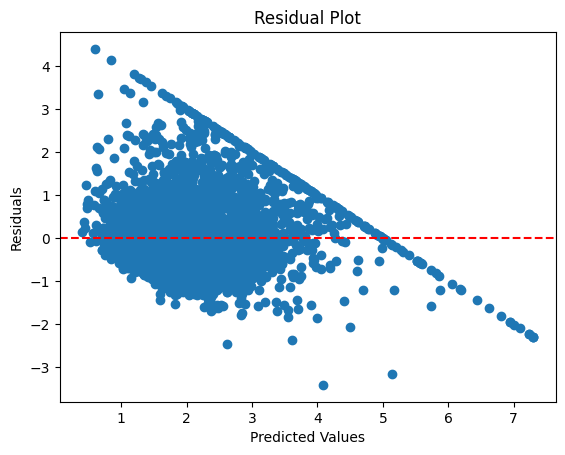

In [24]:
residual = y_test - pred

plt.scatter(pred, residual)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

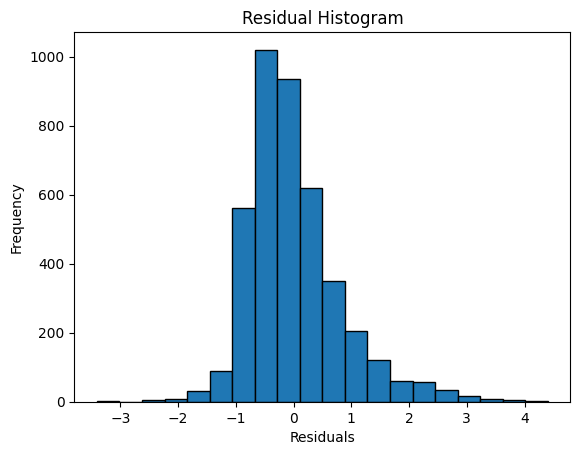

In [25]:
plt.hist(residual, bins=20, edgecolor='black')

plt.xlabel("Residuals")
plt.ylabel("Frequency")

plt.title("Residual Histogram")

plt.show()

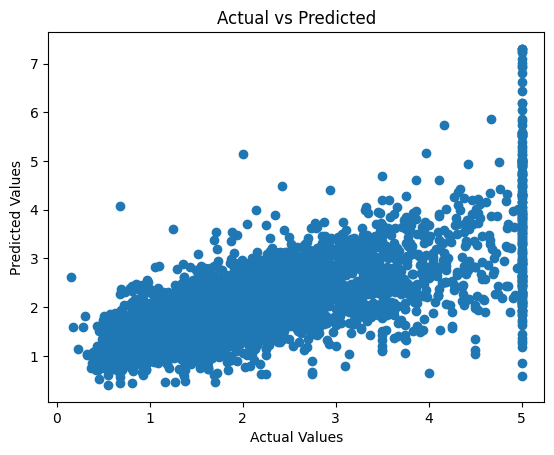

In [26]:
plt.scatter(y_test, pred)

plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")

plt.title("Actual vs Predicted")

plt.show()

In [27]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

for i in range(X_train.shape[1]):
    vif = variance_inflation_factor(X_train.values, i)
    print(X_train.columns[i], "VIF:", vif)

MedInc VIF: 1.0150363262338937
HouseAge VIF: 1.0150363262338935


In [28]:
new_data = pd.DataFrame({
    'MedInc': [5.0],
    'HouseAge': [20]
})

prediction = model.predict(new_data)

print("Predicted House Value:", prediction[0])

print("Value in Dollars:", prediction[0] * 100000)

Predicted House Value: 2.4065314139215768
Value in Dollars: 240653.14139215767
